# cfDNA epithelial signal among high-contribution promoters

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Both panels ask the same question of the per-gene contribution scores behind
the cfDNA classifiers -- does the signal sit where epithelial biology is? --
from two directions: named marker genes, then an unbiased cell-type
enrichment over the top-contributing promoters.

Panels:
- `cfdna_epithelial_marker_percentiles`: six epithelial marker promoters, each
  placed in its task's genome-wide distribution of per-gene contribution
  differences (cancer minus healthy).
- `cfdna_epithelial_celltype_ora`: PanglaoDB cell-type over-representation of
  the top-200 promoters, one row per cancer (all seven). Every cancer gets the
  same pre-specified term, "Epithelial Cells"; the right column counts the
  epithelial terms reaching FDR < 0.05 out of those tested. It replaces an
  earlier version that showed the 12 terms most significant in ovarian cancer
  for four cancers, which repeated one keratin-driven signal twelve times and
  left out the three cancers without signal.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Shared constants ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MARKERS = ["KRT8", "KRT18", "KRT5", "SERPINB5", "SLPI", "TRIM29"]
MARKER_CANCERS = ["Ovarian", "Gastric", "Breast", "Lung", "Bile_duct",
                  "Colorectal", "Pancreatic"]

# Okabe-Ito for the cancers that carry signal; the rest step down through grey,
# which is what says "these three are the null half of the panel" without
# spending a hue on each.
COLORS = {"Ovarian": OKABE_ITO["blue"], "Gastric": OKABE_ITO["purple"],
          "Breast": OKABE_ITO["orange"], "Lung": OKABE_ITO["green"],
          "Bile_duct": "#999999", "Colorectal": "#BBBBBB", "Pancreatic": "#DDDDDD"}

# The two panels were drawn one font size up from the shared paper style.
PANEL_RC = {"xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5}

saved: cfdna/output/cfdna_epithelial_marker_percentiles.pdf
saved: cfdna/output/cfdna_epithelial_marker_percentiles.png
saved: cfdna/output/cfdna_epithelial_marker_percentiles.svg
saved: cfdna/output/cfdna_epithelial_marker_percentiles.tsv


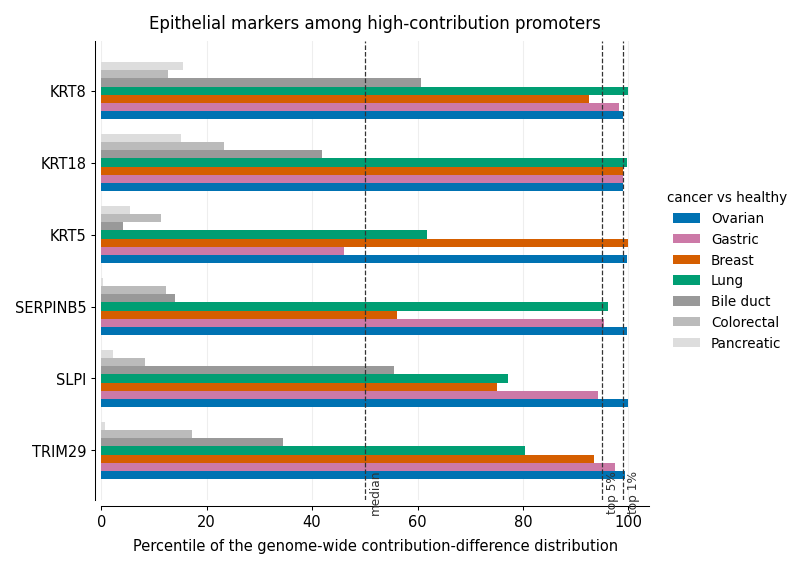

cancer    Ovarian  Gastric  Breast   Lung  Bile_duct  Colorectal  Pancreatic
gene                                                                        
KRT8         98.9     98.2    92.5  100.0       60.7        12.7        15.5
KRT18        99.0     98.9    99.0   99.7       41.9        23.3        15.0
KRT5         99.8     46.1   100.0   61.7        4.1        11.3         5.5
SERPINB5     99.8     95.4    56.1   96.2       14.1        12.2         0.3
SLPI         99.9     94.2    75.0   77.1       55.6         8.3         2.2
TRIM29       99.3     97.5    93.5   80.3       34.5        17.3         0.8


In [3]:
# ── Epithelial marker promoters, by percentile ────────────────────────────────
# The contribution delta is z-scored separately per model, so the raw delta does
# not compare across cancers; the percentile within that task's genome-wide
# distribution does, and it reads directly as "top N% of the genome".
t = pd.read_csv(DATA / "cfdna_epithelial_marker_percentiles.csv")

with plt.rc_context(PANEL_RC):
    fig, ax = plt.subplots(figsize=(5.4, 3.8))
    n = len(MARKER_CANCERS)
    h = 0.80 / n
    for i, c in enumerate(MARKER_CANCERS):
        s = t[t.cancer == c].set_index("gene").reindex(MARKERS)
        y = np.arange(len(MARKERS)) + (n - 1 - i) * h - 0.80 / 2 + h / 2
        ax.barh(y, s.percentile.values, height=h, color=COLORS[c],
                edgecolor="none", label=c.replace("_", " "), zorder=3)

    for v, lab in [(50, "median"), (95, "top 5%"), (99, "top 1%")]:
        ax.axvline(v, color="#333333", linestyle="--", linewidth=0.6, zorder=4)
        ax.annotate(lab, (v, len(MARKERS) - 0.42), xytext=(2, 0),
                    textcoords="offset points", fontsize=5.8, color="#333333",
                    va="center", rotation=90, ha="left")

    ax.set_yticks(np.arange(len(MARKERS)))
    ax.set_yticklabels(MARKERS)
    ax.invert_yaxis()
    ax.set_xlim(0, 104)
    ax.set_xlabel("Percentile of the genome-wide contribution-difference distribution")
    ax.set_title("Epithelial markers among high-contribution promoters", fontsize=8)
    ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5),
              title="cancer vs healthy", title_fontsize=6.5)
    ax.grid(axis="x", color="#EEEEEE", linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["left"].set_position(("outward", 3))
    ax.spines["bottom"].set_position(("outward", 3))
    ax.tick_params(axis="both", which="both", length=2, pad=2)
    fig.tight_layout()
    savefig(fig, OUT, "cfdna_epithelial_marker_percentiles", data=t)
    plt.show()

print(t.pivot(index="gene", columns="cancer", values="percentile")
       .reindex(MARKERS)[MARKER_CANCERS].round(1).to_string())

saved: cfdna/output/cfdna_epithelial_celltype_ora.pdf
saved: cfdna/output/cfdna_epithelial_celltype_ora.png
saved: cfdna/output/cfdna_epithelial_celltype_ora.svg
saved: cfdna/output/cfdna_epithelial_celltype_ora.tsv


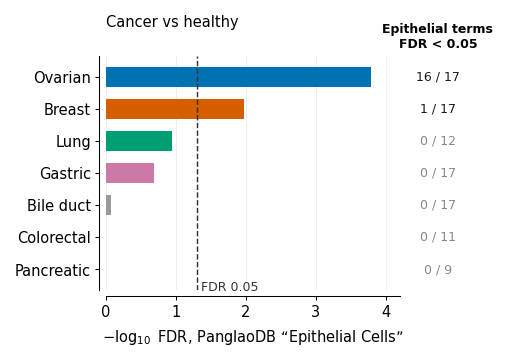

    cancer             term      fdr  neglog10_fdr overlap  n_epithelial_terms_tested  n_epithelial_terms_sig  n_terms_tested
   Ovarian Epithelial Cells 0.000164      3.784664  12/218                         17                      16             156
    Breast Epithelial Cells 0.010583      1.975386  10/218                         17                       1             148
      Lung Epithelial Cells 0.112016      0.950720   7/218                         12                       0             156
   Gastric Epithelial Cells 0.201818      0.695040   6/218                         17                       0             165
 Bile_duct Epithelial Cells 0.836409      0.077581   3/218                         17                       0             139
Colorectal Epithelial Cells 1.000000     -0.000000       0                         11                       0             126
Pancreatic Epithelial Cells 1.000000     -0.000000       0                          9                       0         

In [4]:
# ── Epithelial cell-type over-representation, one row per cancer ─────────────
# Drawn as src/cfdna/fig_celltype_by_cancer.py, with its rcParams.
import matplotlib.transforms as mtransforms

ORA_RC = {"font.family": "sans-serif",
          "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
          "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
          "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
          "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
          "axes.spines.top": False, "axes.spines.right": False}
FDR = 0.05
df = pd.read_csv(DATA / "cfdna_epithelial_celltype_ora.csv")
assert len(df) == 7 and set(df.term) == {"Epithelial Cells"}

with plt.rc_context(ORA_RC):
    fig, ax = plt.subplots(figsize=(3.5, 2.4))
    fig.subplots_adjust(left=0.24, right=0.80, bottom=0.2, top=0.85)
    y = np.arange(len(df))
    ax.barh(y, df.neglog10_fdr, height=0.62, color=[COLORS[c] for c in df.cancer],
            edgecolor="none", zorder=3)
    ax.axvline(-np.log10(FDR), color="#333333", ls="--", lw=0.7, zorder=4)
    ax.text(-np.log10(FDR), len(df) - 0.45, " FDR 0.05", fontsize=6, color="#333333",
            va="center", ha="left")
    tr = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
    ax.text(1.13, -0.8, "Epithelial terms\nFDR < 0.05", transform=tr, ha="center", va="bottom",
            fontsize=6, fontweight="bold")
    for yi, r in zip(y, df.itertuples()):
        ax.text(1.13, yi, f"{r.n_epithelial_terms_sig} / {r.n_epithelial_terms_tested}", transform=tr,
                ha="center", va="center", fontsize=6,
                color="#1A1A1A" if r.n_epithelial_terms_sig else "#888888")
    ax.set_yticks(y); ax.set_yticklabels([c.replace("_", " ") for c in df.cancer])
    ax.invert_yaxis()
    ax.set_xlim(0, 4.2); ax.set_xticks([0, 1, 2, 3, 4])
    ax.set_xlabel("$-\\log_{10}$ FDR, PanglaoDB \u201cEpithelial Cells\u201d")
    ax.set_title("Cancer vs healthy", fontsize=7, loc="left", pad=14)
    ax.grid(axis="x", color="#EEEEEE", lw=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["left"].set_position(("outward", 3)); ax.spines["bottom"].set_position(("outward", 3))
    ax.tick_params(axis="both", which="both", length=2, pad=2)
    savefig(fig, OUT, "cfdna_epithelial_celltype_ora", data=df)
    plt.show()

print(df.drop(columns="genes").to_string(index=False))